# Aprendizagem de Máquina I

## Hugo Tremonte de Carvalho

#### hugo@dme.ufrj.br

O [Breast Cancer Wisconsin Dataset](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic) é um conjunto de dados real, amplamente usado em aprendizado de máquina para tarefas de classificação binária. Ele contém informações obtidas a partir de imagens digitais de biópsias de tumores mamários, com o objetivo de distinguir entre tumores malignos e benignos.

Cada amostra representa o resultado da análise de núcleos de células presentes na imagem, de onde foram extraídas 30 características numéricas relacionadas à forma, textura e estrutura dos núcleos. O conjunto inclui 569 amostras, sendo aproximadamente 62% benignas e 38% malignas.

As covariáveis são estatísticas-resumo de:
* `radius` (distâncias do cento até o perímetro)
* `texture` (tons de cinza da imagem)
* `perimeter`
* `area`
* `smoothness` (variacão local de raio)
* `compactness` (perímetro²/área - 1.0)
* `concavity` (grau de concavidade dos contornos)
* `concave points` (número de porçoes côncavas no contorno)
* `symmetry`
* `fractal dimension` ("coastline approximation" - 1)

_The mean, standard error, and "worst" or largest (mean of the three worst/largest values) of these features were computed for each image, resulting in 30 features._

In [ ]:
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

from sklearn.datasets import load_breast_cancer

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay, confusion_matrix, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import numpy as np

import seaborn as sns

In [ ]:
########## PRETTY MATRIX DISPLAY ##########
# Source: https://gist.github.com/braingineer/d801735dac07ff3ac4d746e1f218ab75
def matprint(mat, fmt="g", round_dig = 0):
    col_maxes = [max([len(("{:"+fmt+"}").format(x)) for x in col]) for col in mat.T]
    for x in mat:
        for i, y in enumerate(x):
            if round_dig == 0:
                print(("{:"+str(col_maxes[i])+fmt+"}").format(y), end="  ")
            else:
                print(("{:"+str(col_maxes[i])+fmt+"}").format(round(y, round_dig)), end="  ")
        print("")
###########################################

########## CONFUSION MATRIX METRICS ##########
class ConfusionMatrixMetrics:
    def __init__(self, matrix):
        """
        Inicializa a classe com uma matriz de confusão 2x2.
        A matriz deve estar no formato:
        [[VN, FP],
         [FN, VP]]
        onde:
        - VP: Verdadeiros Positivos
        - FP: Falsos Positivos
        - FN: Falsos Negativos
        - VN: Verdadeiros Negativos
        """
        self.matrix = matrix

        self.VN = self.matrix[0][0]
        self.FP = self.matrix[0][1]
        self.FN = self.matrix[1][0]
        self.VP = self.matrix[1][1]

        self.N = self.matrix[0][0] + self.matrix[0][1]
        self.P = self.matrix[1][0] + self.matrix[1][1]

        self.Pop = self.N + self.P

    def prev(self):
        """Calcula a prevalência da classe positiva"""
        try:
            return (self.P)/(self.Pop)
        except ZeroDivisionError:
            return 0.0

    def acc(self):
        """Calcula a acurária"""
        try:
            return (self.VN + self.VP)/self.Pop
        except ZeroDivisionError:
            return 0.0

    def FPR(self):
        """Calcula a FPR"""
        try:
            return self.FP/self.N
        except ZeroDivisionError:
            return 0.0

    def TNR(self):
        """Calcula a TNR"""
        try:
            return self.VN/self.N
        except ZeroDivisionError:
            return 0.0

    def TPR(self):
        """Calcula a TPR"""
        try:
            return self.VP/self.P
        except ZeroDivisionError:
            return 0.0

    def FNR(self):
        """Calcula a FNR"""
        try:
            return self.FN/self.P
        except ZeroDivisionError:
            return 0.0

    def FOR(self):
        """Calcula a FOR"""
        try:
            return self.FN/(self.VN + self.FN)
        except ZeroDivisionError:
            return 0.0

    def PPV(self):
        """Calcula o PPV"""
        try:
            return self.VP/(self.FP + self.VP)
        except ZeroDivisionError:
            return 0.0

    def NPV(self):
        """Calcula a NPV"""
        try:
            return self.VN/(self.VN + self.FN)
        except ZeroDivisionError:
            return 0.0

    def FDR(self):
        """Calcula a FDR"""
        try:
            return self.FP/(self.FP + self.VP)
        except ZeroDivisionError:
            return 0.0

    def F1(self):
        """Calcula a F1"""
        try:
            return 2/(1/self.PPV() + 1/self.TPR())
        except ZeroDivisionError:
            return np.NaN

    def print(self):
        """Mostra todas as métricas calculadas acima"""
        print('Matriz de confusão:')
        matprint(self.matrix)

        print('\n')

        print('Prevalência:', np.round(self.prev(), 3))
        print('Acurácia:', np.round(self.acc(), 3))

        print('\n')

        print('Taxa de falsos positivos:', np.round(self.FPR(), 3))
        print('Taxa de verdadeiros negativos (Especificidade):',np.round(self.TNR(), 3))
        print('Taxa de verdadeiros positivos (Recall):', np.round(self.TPR(), 3))
        print('Taxa de falsos negativos:', np.round(self.FNR(), 3))

        print('\n')

        print('False omission rate:', np.round(self.FOR(), 3))
        print('Valor preditivo positivo (Precisão):', np.round(self.PPV(), 3))
        print('Valor preditivo negativo:', np.round(self.NPV(), 3))
        print('False discovery rate:', np.round(self.FDR(), 3))

        print('\n')

        print('F1 Score:', np.round(self.F1(), 3))
    ##############################################

a) Carregue a base de dados e faça uma análise exploratória.

In [ ]:
data = load_breast_cancer(as_frame = True)

In [ ]:
data

{'data':      mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
 0          17.99         10.38          122.80     1001.0          0.11840   
 1          20.57         17.77          132.90     1326.0          0.08474   
 2          19.69         21.25          130.00     1203.0          0.10960   
 3          11.42         20.38           77.58      386.1          0.14250   
 4          20.29         14.34          135.10     1297.0          0.10030   
 ..           ...           ...             ...        ...              ...   
 564        21.56         22.39          142.00     1479.0          0.11100   
 565        20.13         28.25          131.20     1261.0          0.09780   
 566        16.60         28.08          108.30      858.1          0.08455   
 567        20.60         29.33          140.10     1265.0          0.11780   
 568         7.76         24.54           47.92      181.0          0.05263   
 
      mean compactness  mean concavity  me

In [ ]:
data = data.frame

In [ ]:
data.shape

(569, 31)

In [ ]:
data.isna().sum().sum()

np.int64(0)

In [ ]:
data.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
sns.pairplot(data = data, hue = 'target')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
data.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [ ]:
data['target'].value_counts()

# https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
# 0 = maligno
# 1 = benigno

,count
target,
1,357
0,212


b) Treine e avalie o desempenho do SVM, com kernel linear

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data.drop(columns = ['target']), data['target'], test_size=0.3)

In [ ]:
SVC_linear_pipe = Pipeline([('Scaler', StandardScaler()), ('SVC', SVC(kernel = 'linear'))])

# COMPARAR COM https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html

param_grid_linear = {
    'SVC__C': np.logspace(-1, 2, 30),
}

SVC_pipe_linear_CV = GridSearchCV(SVC_linear_pipe, param_grid = param_grid_linear, cv=5, scoring='accuracy', n_jobs=-1)
SVC_pipe_linear_CV.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('Scaler', StandardScaler()),
                                       ('SVC', SVC(kernel='linear'))]),
             n_jobs=-1,
             param_grid={'SVC__C': array([  0.1       ,   0.1268961 ,   0.1610262 ,   0.20433597,
         0.25929438,   0.32903446,   0.41753189,   0.52983169,
         0.67233575,   0.85316785,   1.08263673,   1.3738238 ,
         1.74332882,   2.21221629,   2.8072162 ,   3.56224789,
         4.52035366,   5.73615251,   7.27895384,   9.23670857,
        11.72102298,  14.87352107,  18.87391822,  23.9502662 ,
        30.39195382,  38.56620421,  48.93900918,  62.10169419,
        78.80462816, 100.        ])},
             scoring='accuracy')

In [ ]:
np.logspace(-1, 2, 30)

array([  0.1       ,   0.1268961 ,   0.1610262 ,   0.20433597,
         0.25929438,   0.32903446,   0.41753189,   0.52983169,
         0.67233575,   0.85316785,   1.08263673,   1.3738238 ,
         1.74332882,   2.21221629,   2.8072162 ,   3.56224789,
         4.52035366,   5.73615251,   7.27895384,   9.23670857,
        11.72102298,  14.87352107,  18.87391822,  23.9502662 ,
        30.39195382,  38.56620421,  48.93900918,  62.10169419,
        78.80462816, 100.        ])

In [ ]:
CM_SVC_linear = confusion_matrix(y_test, SVC_pipe_linear_CV.predict(X_test))

ConfusionMatrixMetrics(CM_SVC_linear).print()

Matriz de confusão:
57    4  
 3  107  


Prevalência: 0.643
Acurácia: 0.959


Taxa de falsos positivos: 0.066
Taxa de verdadeiros negativos (Especificidade): 0.934
Taxa de verdadeiros positivos (Recall): 0.973
Taxa de falsos negativos: 0.027


False omission rate: 0.05
Valor preditivo positivo (Precisão): 0.964
Valor preditivo negativo: 0.95
False discovery rate: 0.036


F1 Score: 0.968


c) Verifique o desempenho do SVM com outros kernel (polinomial e rbf)

In [ ]:
SVC_poly_pipe = Pipeline([('Scaler', StandardScaler()), ('SVC', SVC(kernel = 'poly'))])

param_grid_poly = {
    'SVC__gamma': ['auto', 'scale', *np.logspace(-5,-1,5)],
    'SVC__C': np.logspace(-1, 2, 5),
    'SVC__degree': [2,3,4],
    'SVC__coef0': np.logspace(-2, 2, 5)
}

SVC_pipe_poly_CV = GridSearchCV(SVC_poly_pipe, param_grid = param_grid_poly, cv=5, scoring='accuracy', n_jobs=-1)
SVC_pipe_poly_CV.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('Scaler', StandardScaler()),
                                       ('SVC', SVC(kernel='poly'))]),
             n_jobs=-1,
             param_grid={'SVC__C': array([  0.1       ,   0.56234133,   3.16227766,  17.7827941 ,
       100.        ]),
                         'SVC__coef0': array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02]),
                         'SVC__degree': [2, 3, 4],
                         'SVC__gamma': ['auto', 'scale', np.float64(1e-05),
                                        np.float64(0.0001), np.float64(0.001),
                                        np.float64(0.01), np.float64(0.1)]},
             scoring='accuracy')

In [ ]:
CM_SVC_poly = confusion_matrix(y_test, SVC_pipe_poly_CV.predict(X_test))

ConfusionMatrixMetrics(CM_SVC_poly).print()

Matriz de confusão:
57    4  
 3  107  


Prevalência: 0.643
Acurácia: 0.959


Taxa de falsos positivos: 0.066
Taxa de verdadeiros negativos (Especificidade): 0.934
Taxa de verdadeiros positivos (Recall): 0.973
Taxa de falsos negativos: 0.027


False omission rate: 0.05
Valor preditivo positivo (Precisão): 0.964
Valor preditivo negativo: 0.95
False discovery rate: 0.036


F1 Score: 0.968


In [ ]:
SVC_rbf_pipe = Pipeline([('Scaler', StandardScaler()), ('SVC', SVC(kernel = 'rbf'))])

param_grid_rbf = {
    'SVC__C': np.logspace(-1, 2, 20),
    'SVC__gamma': ['auto', 'scale', *np.logspace(-5, 1, 20)]
}

SVC_rbf_pipe_CV = GridSearchCV(SVC_rbf_pipe, param_grid = param_grid_rbf, cv=5, scoring='accuracy', n_jobs=-1)
SVC_rbf_pipe_CV.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('Scaler', StandardScaler()),
                                       ('SVC', SVC())]),
             n_jobs=-1,
             param_grid={'SVC__C': array([  0.1       ,   0.14384499,   0.20691381,   0.29763514,
         0.42813324,   0.61584821,   0.88586679,   1.27427499,
         1.83298071,   2.6366509 ,   3.79269019,   5.45559478,
         7.8475997 ,  11.28837892,  16.23776739,  23.35721469,
        33.59818286,  48.32930239,  69.51927962, 100.        ]),
                         'SVC__gamma...
                                        np.float64(0.0069519279617756054),
                                        np.float64(0.01438449888287663),
                                        np.float64(0.029763514416313162),
                                        np.float64(0.06158482110660261),
                                        np.float64(0.1274274985703132),
                                        np.float64(0.26366508987303555),
                                        np.float64(0.5455594781168515),
                                        np.float64(1.1288378916846884),
                                        np.float64(2.3357214690901213),
                                        np.float64(4.832930238571752),
                                        np.float64(10.0)]},
             scoring='accuracy')

In [ ]:
CM_SVC_rbf = confusion_matrix(y_test, SVC_rbf_pipe_CV.predict(X_test))

ConfusionMatrixMetrics(CM_SVC_rbf).print()

Matriz de confusão:
57    4  
 2  108  


Prevalência: 0.643
Acurácia: 0.965


Taxa de falsos positivos: 0.066
Taxa de verdadeiros negativos (Especificidade): 0.934
Taxa de verdadeiros positivos (Recall): 0.982
Taxa de falsos negativos: 0.018


False omission rate: 0.034
Valor preditivo positivo (Precisão): 0.964
Valor preditivo negativo: 0.966
False discovery rate: 0.036


F1 Score: 0.973


In [ ]:
NB_pipe = Pipeline([('Scaler', StandardScaler()), ('NB', GaussianNB())])

NB_pipe.fit(X_train, y_train)

Pipeline(steps=[('Scaler', StandardScaler()), ('NB', GaussianNB())])

In [ ]:
CM_NB = confusion_matrix(y_test, NB_pipe.predict(X_test))

ConfusionMatrixMetrics(CM_NB).print()

Matriz de confusão:
51   10  
 1  109  


Prevalência: 0.643
Acurácia: 0.936


Taxa de falsos positivos: 0.164
Taxa de verdadeiros negativos (Especificidade): 0.836
Taxa de verdadeiros positivos (Recall): 0.991
Taxa de falsos negativos: 0.009


False omission rate: 0.019
Valor preditivo positivo (Precisão): 0.916
Valor preditivo negativo: 0.981
False discovery rate: 0.084


F1 Score: 0.952


d) Verifique o desempenho dos modelos baseados em árvores e do KNN

In [ ]:
KNN_pipe = Pipeline([('Scaler', StandardScaler()),
                     ('KNN', KNeighborsClassifier())])

param_grid_KNN = {
    'KNN__n_neighbors': range(1,11),
    'KNN__weights': ['uniform', 'distance'],
    'KNN__p': [1,2,3,4,5],
}

KNN_pipe_CV = GridSearchCV(KNN_pipe, param_grid = param_grid_KNN, cv = 5,
                           scoring = 'f1', n_jobs = -1)
KNN_pipe_CV.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('Scaler', StandardScaler()),
                                       ('KNN', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'KNN__n_neighbors': range(1, 11),
                         'KNN__p': [1, 2, 3, 4, 5],
                         'KNN__weights': ['uniform', 'distance']},
             scoring='f1')

In [ ]:
CM_KNN = confusion_matrix(y_test, KNN_pipe_CV.predict(X_test))

ConfusionMatrixMetrics(CM_KNN).print()

Matriz de confusão:
55    6  
 1  109  


Prevalência: 0.643
Acurácia: 0.959


Taxa de falsos positivos: 0.098
Taxa de verdadeiros negativos (Especificidade): 0.902
Taxa de verdadeiros positivos (Recall): 0.991
Taxa de falsos negativos: 0.009


False omission rate: 0.018
Valor preditivo positivo (Precisão): 0.948
Valor preditivo negativo: 0.982
False discovery rate: 0.052


F1 Score: 0.969


In [ ]:
DT_Pipe = Pipeline([('Scaler', StandardScaler()),
                   ('DT', DecisionTreeClassifier(min_samples_leaf=5))])

param_grid_DT = {
    'DT__criterion': ['gini', 'entropy'],
    'DT__ccp_alpha': np.logspace(-10,-5,10)
}

DT_pipe_CV = GridSearchCV(DT_Pipe, param_grid = param_grid_DT, cv =5,
                          scoring = 'accuracy', n_jobs = -1)

DT_pipe_CV.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('Scaler', StandardScaler()),
                                       ('DT',
                                        DecisionTreeClassifier(min_samples_leaf=5))]),
             n_jobs=-1,
             param_grid={'DT__ccp_alpha': array([1.00000000e-10, 3.59381366e-10, 1.29154967e-09, 4.64158883e-09,
       1.66810054e-08, 5.99484250e-08, 2.15443469e-07, 7.74263683e-07,
       2.78255940e-06, 1.00000000e-05]),
                         'DT__criterion': ['gini', 'entropy']},
             scoring='accuracy')

In [ ]:
CM_DT = confusion_matrix(y_test, DT_pipe_CV.predict(X_test))

ConfusionMatrixMetrics(CM_DT).print()

Matriz de confusão:
55    6  
 4  106  


Prevalência: 0.643
Acurácia: 0.942


Taxa de falsos positivos: 0.098
Taxa de verdadeiros negativos (Especificidade): 0.902
Taxa de verdadeiros positivos (Recall): 0.964
Taxa de falsos negativos: 0.036


False omission rate: 0.068
Valor preditivo positivo (Precisão): 0.946
Valor preditivo negativo: 0.932
False discovery rate: 0.054


F1 Score: 0.955


In [ ]:
RF_pipe = Pipeline([('Scaler', StandardScaler()),
                   ('RF', RandomForestClassifier(n_estimators= 5000,
                                                 criterion='entropy'))])

RF_pipe.fit(X_train, y_train)

Pipeline(steps=[('Scaler', StandardScaler()),
                ('RF',
                 RandomForestClassifier(criterion='entropy',
                                        n_estimators=5000))])

In [ ]:
CM_RF = confusion_matrix(y_test, RF_pipe.predict(X_test))

ConfusionMatrixMetrics(CM_RF).print()

Matriz de confusão:
55    6  
 0  110  


Prevalência: 0.643
Acurácia: 0.965


Taxa de falsos positivos: 0.098
Taxa de verdadeiros negativos (Especificidade): 0.902
Taxa de verdadeiros positivos (Recall): 1.0
Taxa de falsos negativos: 0.0


False omission rate: 0.0
Valor preditivo positivo (Precisão): 0.948
Valor preditivo negativo: 1.0
False discovery rate: 0.052


F1 Score: 0.973


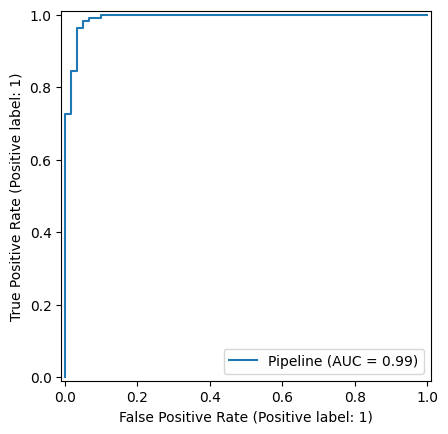

In [ ]:
RocCurveDisplay.from_estimator(RF_pipe, X_test, y_test)

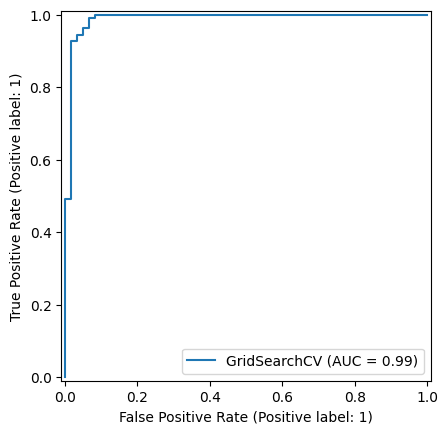

In [ ]:
RocCurveDisplay.from_estimator(SVC_pipe_linear_CV, X_test, y_test)